# 03 - Inventory optimization: forecast-based safety stock vs. the current rule

**Business question.** If replenishment used the new forecast and its measured error instead of
the planners' weeks-of-cover rule, how much inventory (and excess inventory) could be removed
without hurting service?

**Current rule (from the planning team).** Each week, reorder when inventory position falls below
`avg8 x (lead time + 2)` and order up to `avg8 x (lead time + 5)`, where `avg8` is trailing 8-week
average demand. It ignores seasonality and forecast error: stock builds up after peaks and is
short on the way up.

**Proposed policy.** Same weekly review and the same order-cycle length (3 weeks of demand per
order), but driven by the forecast and its measured error:

* reorder point `s_t = forecast demand over the lead time + z x sigma_LT`
* order-up-to `S_t = s_t + 3 x forecast weekly demand`

where the forecast is the gradient boosting rolling forecast from notebook 02 and `sigma_LT` is the
RMSE of lead-time forecast errors measured out of sample on the validation quarter (shrunk toward
the category average for stability). `z = 1.645` targets a 95% cycle service level.

**Evaluation.** Both policies are simulated week by week over the 39-week test period
(Mar-Dec 2025) with actual demand, starting from the real inventory snapshot and open purchase
orders at the end of week 116, using the same lead times and case-pack rounding.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

sys.path.insert(0, str(Path("../src").resolve()))
from inventory import simulate

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
START = pd.Timestamp("2023-01-02")
SIM_START = 117          # first simulated week (first test week)
EXCESS_WEEKS = 8         # stock not needed within the next 8 weeks of demand counts as excess

In [2]:
products = pd.read_csv(RAW / "products.csv")
locations = pd.read_csv(RAW / "locations.csv")
snap = pd.read_csv(RAW / "inventory_snapshots.csv", parse_dates=["snapshot_date"])
pos = pd.read_csv(RAW / "purchase_orders.csv", parse_dates=["order_date", "expected_receipt_date"])
weekly = pd.read_csv(PROC / "weekly_sales.csv")
roll = pd.read_csv(PROC / "forecast_rolling.csv")

snap["week"] = (snap.snapshot_date - START).dt.days // 7
pos["order_week"] = (pos.order_date - START).dt.days // 7
pos["receipt_week"] = (pos.expected_receipt_date - START).dt.days // 7

Y = weekly.pivot_table(index=["sku_id", "location_id"], columns="week", values="units").sort_index()
keys = (Y.index.to_frame(index=False)
        .merge(products[["sku_id", "category", "case_pack", "unit_cost"]], on="sku_id")
        .merge(locations[["location_id", "lead_time_weeks"]], on="location_id"))
D = Y.to_numpy(float)
n_series, n_weeks = D.shape
print(n_series, "series |", n_weeks, "weeks | lead times:", keys.lead_time_weeks.value_counts().to_dict())

240 series | 156 weeks | lead times: {2: 120, 3: 60, 1: 60}


## 1. Forecast error over the lead time (validation quarter)

For each series and each validation origin t (weeks 103-115), compare the forecast of total demand
over the next L weeks with what actually happened. The RMSE of that error is the safety-stock
sigma. Series-level estimates use only ~12 points, so they are blended 50/50 with the category
level (relative error x series level).

In [3]:
F = np.full((n_series, n_weeks, 4), np.nan)  # F[i, origin, h-1]
sidx = pd.MultiIndex.from_frame(keys[["sku_id", "location_id"]])
roll["i"] = sidx.get_indexer(pd.MultiIndex.from_frame(roll[["sku_id", "location_id"]]))
F[roll.i.values, roll.origin_week.values, roll.h.values - 1] = roll.forecast.values

L = keys.lead_time_weeks.to_numpy()
val_origins = np.arange(103, 116)
err, lvl = [], []
for i in range(n_series):
    e = [D[i, t + 1 : t + 1 + L[i]].sum() - F[i, t, : L[i]].sum() for t in val_origins if t + L[i] <= 116]
    err.append(np.sqrt(np.mean(np.square(e))))
    lvl.append(np.mean([F[i, t, : L[i]].sum() for t in val_origins]))
keys["sigma_lt_series"] = err
keys["lt_forecast_level"] = lvl
cat_ratio = keys.groupby("category").apply(
    lambda g: np.sqrt((g.sigma_lt_series ** 2).sum() / (g.lt_forecast_level ** 2).sum()), include_groups=False)
keys["sigma_lt"] = 0.5 * keys.sigma_lt_series + 0.5 * keys.category.map(cat_ratio) * keys.lt_forecast_level
print("Relative lead-time forecast error (sigma / mean lead-time demand) by category:")
cat_ratio.sort_values().round(3)

Relative lead-time forecast error (sigma / mean lead-time demand) by category:


category
Stretch Film        0.258
Labels              0.332
Packing Tape        0.335
Food Containers     0.382
Void Fill           0.389
Corrugated Boxes    0.399
Gift Packaging      0.409
Poly Mailers        0.414
dtype: float64

## 2. Starting state and simulator check

Starting on-hand and backorders come from the week-116 snapshot; open purchase orders are those
placed by week 116 and due from week 117 on. As a sanity check, the simulator run with the current
rule should reproduce the real snapshots for the test period.

In [4]:
s0 = snap[snap.week == SIM_START - 1].set_index(["sku_id", "location_id"]).loc[sidx]
open_po = pos[(pos.order_week < SIM_START) & (pos.receipt_week >= SIM_START)]
pipe0 = {k: g.groupby("receipt_week").quantity.sum().to_dict()
         for k, g in open_po.groupby(["sku_id", "location_id"])}

# Forecast lead-time demand and weekly run-rate at every origin week. Near the end of the data
# some horizons are not observable; they fall back to the average of the available horizons.
CYCLE_WEEKS = 3  # same order-cycle length the current rule implies (OUT - ROP = 3 weeks)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)  # final origin has no observable horizon
    rate = np.nanmean(F, axis=2)
rate = pd.DataFrame(rate).T.ffill().T.fillna(0).to_numpy()
FC_RATE = rate
FC_LT = np.zeros_like(rate)
for i in range(n_series):
    f = F[i, :, : L[i]]
    FC_LT[i] = np.where(np.isnan(f), rate[i][:, None], f).sum(axis=1)

def run(policy, z=1.645, rop_extra=2.0, out_extra=5.0):
    res = []
    for i, k in enumerate(sidx):
        kw = dict(lead_time=int(L[i]), case_pack=int(keys.case_pack[i]), start_week=SIM_START,
                  on_hand0=float(s0.on_hand_units.iloc[i]), backorder0=float(s0.backorder_units.iloc[i]),
                  pipeline0=pipe0.get(k, {}))
        if policy == "current":
            out = simulate(D[i], policy="weeks_of_cover", rop_extra=rop_extra, out_extra=out_extra, **kw)
        else:
            lt_demand, weekly_rate = FC_LT[i], FC_RATE[i]
            rop = lt_demand + z * keys.sigma_lt[i]
            out = simulate(D[i], policy="forecast_min_max", reorder_point=rop,
                           order_up_to=rop + CYCLE_WEEKS * weekly_rate, **kw)
        weeks = np.arange(SIM_START, n_weeks)
        res.append(pd.DataFrame({"sku_id": k[0], "location_id": k[1], "week": weeks,
                                 "demand": D[i, SIM_START:], **{c: out[c] for c in
                                 ["on_hand", "on_order", "backorder", "filled", "receipts", "ordered"]}}))
    df = pd.concat(res, ignore_index=True).merge(keys[["sku_id", "location_id", "category", "unit_cost"]],
                                                 on=["sku_id", "location_id"])
    # forward-looking excess: stock not needed within the next EXCESS_WEEKS weeks of demand
    df = df.sort_values(["sku_id", "location_id", "week"])
    fwd = (df.groupby(["sku_id", "location_id"]).demand
             .transform(lambda s: s[::-1].rolling(EXCESS_WEEKS, min_periods=EXCESS_WEEKS).sum()[::-1].shift(-1)))
    df["excess_units"] = (df.on_hand - fwd).clip(lower=0)
    df["has_full_lookahead"] = fwd.notna()
    df["inventory_value"] = df.on_hand * df.unit_cost
    df["excess_value"] = df.excess_units * df.unit_cost
    return df

current = run("current")
chk = current.merge(snap[["sku_id", "location_id", "week", "on_hand_units"]], on=["sku_id", "location_id", "week"])
print("Simulated vs. actual on-hand, mean abs. difference (units):",
      round((chk.on_hand - chk.on_hand_units).abs().mean(), 2),
      "| relative:", round((chk.on_hand - chk.on_hand_units).abs().sum() / chk.on_hand_units.sum(), 5))

Simulated vs. actual on-hand, mean abs. difference (units): 0.27 | relative: 4e-05


The simulator reproduces the recorded snapshots (differences are rounding), so the comparison
below is like-for-like.

## 3. Proposed policy at a 95% cycle-service target

In [5]:
proposed = run("proposed", z=norm.ppf(0.95))

def kpis(df):
    w = df[df.has_full_lookahead]  # weeks where the 8-week excess look-ahead is fully observed
    return pd.Series({
        "avg inventory value (USD)": df.groupby("week").inventory_value.sum().mean(),
        "avg excess value (USD)": w.groupby("week").excess_value.sum().mean(),
        "excess share of inventory": w.excess_value.sum() / w.inventory_value.sum(),
        "unit fill rate": df.filled.sum() / df.demand.sum(),
        "weeks of cover (avg)": df.on_hand.sum() / df.demand.sum(),
        "SKU-loc-weeks with backorder": (df.backorder > 0).mean(),
        "POs placed": (df.ordered > 0).sum(),
    })

comp = pd.DataFrame({"current rule": kpis(current), "forecast-based (z=1.645)": kpis(proposed)})
comp["change"] = comp.iloc[:, 1] / comp.iloc[:, 0] - 1
comp.round(4)

,current rule,forecast-based (z=1.645),change
avg inventory value (USD),2.990910e+06,2.402495e+06,-0.1967
avg excess value (USD),3.640822e+04,2.978733e+04,-0.1819
excess share of inventory,1.330000e-02,1.290000e-02,-0.0335
unit fill rate,9.964000e-01,9.980000e-01,0.0016
weeks of cover (avg),3.581100e+00,2.941300e+00,-0.1787
SKU-loc-weeks with backorder,1.060000e-02,7.600000e-03,-0.2828
POs placed,2.628000e+03,2.407000e+03,-0.0841


## 4. Service vs. inventory trade-off

A single comparison point can flatter either policy, so both are swept: the current rule over a
range of weeks-of-cover settings, and the proposed policy over service targets. Comparing the curves
at equal fill rate isolates the value of the better forecast and explicit error-based buffers.

In [6]:
frontier = []
for rop, out in [(0.5, 2.5), (1.0, 3.0), (1.5, 4.0), (2.0, 5.0), (3.0, 6.0), (4.0, 8.0)]:
    k = kpis(run("current", rop_extra=rop, out_extra=out))
    frontier.append({"policy": "current rule", "setting": f"ROP L+{rop:g}, OUT L+{out:g}", **k})
for sl in [0.70, 0.80, 0.90, 0.95, 0.975, 0.99]:
    k = kpis(run("proposed", z=norm.ppf(sl)))
    frontier.append({"policy": "forecast-based", "setting": f"{sl:.1%} cycle service", **k})
frontier = pd.DataFrame(frontier)
frontier[["policy", "setting", "avg inventory value (USD)", "avg excess value (USD)", "unit fill rate"]].round(3)

,policy,setting,avg inventory value (USD),avg excess value (USD),unit fill rate
0,current rule,"ROP L+0.5, OUT L+2.5",1531875.818,28344.065,0.968
1,current rule,"ROP L+1, OUT L+3",1882016.048,28451.412,0.984
2,current rule,"ROP L+1.5, OUT L+4",2425586.681,30048.718,0.992
3,current rule,"ROP L+2, OUT L+5",2990909.621,36408.218,0.996
4,current rule,"ROP L+3, OUT L+6",3768962.330,67370.188,0.999
5,current rule,"ROP L+4, OUT L+8",4965725.165,222725.914,1.000
6,forecast-based,70.0% cycle service,1948448.802,28786.989,0.986
7,forecast-based,80.0% cycle service,2070936.949,28968.716,0.991
8,forecast-based,90.0% cycle service,2251280.426,29290.830,0.996
9,forecast-based,95.0% cycle service,2402495.115,29787.327,0.998


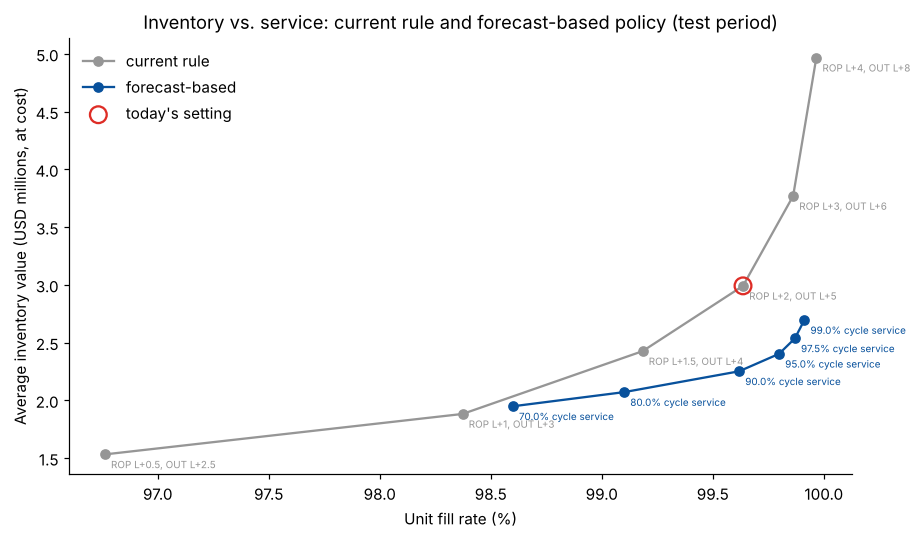

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 5))
for pol, c in [("current rule", "#969696"), ("forecast-based", "#08519c")]:
    f = frontier[frontier.policy == pol].sort_values("unit fill rate")
    ax.plot(f["unit fill rate"] * 100, f["avg inventory value (USD)"] / 1e6, marker="o", color=c, label=pol)
    for _, r in f.iterrows():
        ax.annotate(r.setting, (r["unit fill rate"] * 100, r["avg inventory value (USD)"] / 1e6),
                    fontsize=6.5, xytext=(4, -9), textcoords="offset points", color=c)
cur = frontier[(frontier.policy == "current rule") & (frontier.setting == "ROP L+2, OUT L+5")].iloc[0]
ax.scatter([cur["unit fill rate"] * 100], [cur["avg inventory value (USD)"] / 1e6], s=120,
           facecolor="none", edgecolor="#de2d26", lw=1.5, label="today's setting", zorder=5)
ax.set_title("Inventory vs. service: current rule and forecast-based policy (test period)")
ax.set_xlabel("Unit fill rate (%)"); ax.set_ylabel("Average inventory value (USD millions, at cost)")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "03_service_inventory_frontier.png", bbox_inches="tight")
plt.show()

## 5. Equal-service comparison

Interpolate the forecast-based curve at the fill rate the current rule achieves today, then
re-run the proposed policy at that service target to report realised numbers.

In [8]:
cur_fill = comp.loc["unit fill rate", "current rule"]
f = frontier[frontier.policy == "forecast-based"].sort_values("unit fill rate")
sl_grid = np.array([0.70, 0.80, 0.90, 0.95, 0.975, 0.99])
fills = f["unit fill rate"].to_numpy()
sl_match = float(np.interp(cur_fill, fills, np.sort(sl_grid)))
matched = run("proposed", z=norm.ppf(sl_match))
eq = pd.DataFrame({"current rule": kpis(current), f"forecast-based ({sl_match:.1%} target)": kpis(matched)})
eq["change"] = eq.iloc[:, 1] / eq.iloc[:, 0] - 1
eq.round(4)

,current rule,forecast-based (90.5% target),change
avg inventory value (USD),2.990910e+06,2.260870e+06,-0.2441
avg excess value (USD),3.640822e+04,2.932340e+04,-0.1946
excess share of inventory,1.330000e-02,1.350000e-02,0.0114
unit fill rate,9.964000e-01,9.963000e-01,-0.0001
weeks of cover (avg),3.581100e+00,2.761800e+00,-0.2288
SKU-loc-weeks with backorder,1.060000e-02,1.290000e-02,0.2222
POs placed,2.628000e+03,2.390000e+03,-0.0906


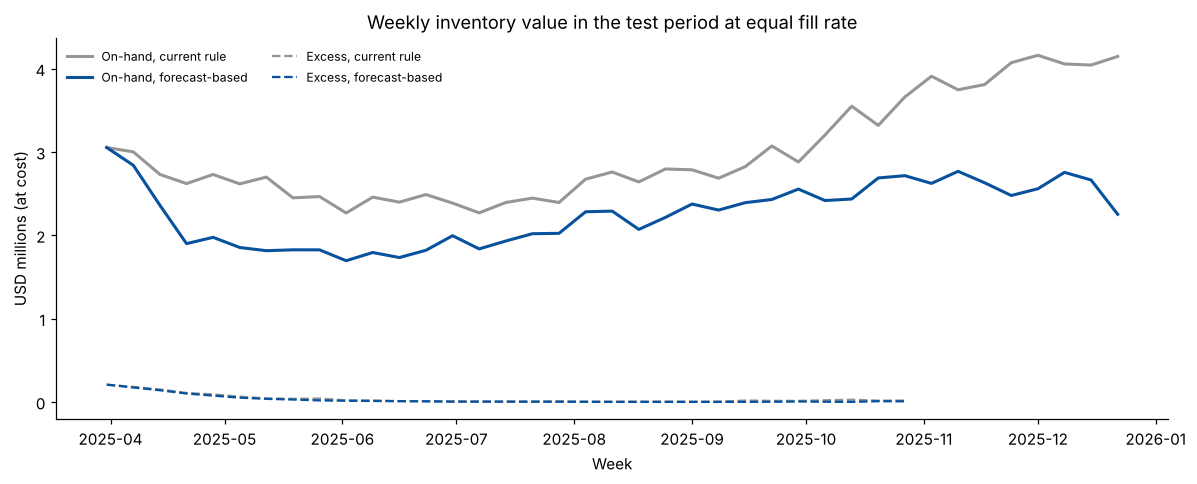

In [9]:
wk = pd.DataFrame({
    "current: on-hand": current.groupby("week").inventory_value.sum(),
    "forecast-based: on-hand": matched.groupby("week").inventory_value.sum(),
    "current: excess": current[current.has_full_lookahead].groupby("week").excess_value.sum(),
    "forecast-based: excess": matched[matched.has_full_lookahead].groupby("week").excess_value.sum(),
}) / 1e6
wk.index = START + pd.to_timedelta(wk.index * 7, unit="D")
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(wk.index, wk["current: on-hand"], color="#969696", lw=2, label="On-hand, current rule")
ax.plot(wk.index, wk["forecast-based: on-hand"], color="#08519c", lw=2, label="On-hand, forecast-based")
ax.plot(wk.index, wk["current: excess"], color="#969696", ls="--", label="Excess, current rule")
ax.plot(wk.index, wk["forecast-based: excess"], color="#08519c", ls="--", label="Excess, forecast-based")
ax.set_title("Weekly inventory value in the test period at equal fill rate")
ax.set_xlabel("Week"); ax.set_ylabel("USD millions (at cost)"); ax.legend(frameon=False, ncol=2, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "03_inventory_over_time.png", bbox_inches="tight")
plt.show()

In [10]:
by_cat = pd.DataFrame({
    "current_inv": current.groupby("category").inventory_value.mean(),
    "proposed_inv": matched.groupby("category").inventory_value.mean(),
    "current_excess": current[current.has_full_lookahead].groupby("category").excess_value.mean(),
    "proposed_excess": matched[matched.has_full_lookahead].groupby("category").excess_value.mean(),
    "current_fill": current.groupby("category").filled.sum() / current.groupby("category").demand.sum(),
    "proposed_fill": matched.groupby("category").filled.sum() / matched.groupby("category").demand.sum(),
})
by_cat["inv_change"] = by_cat.proposed_inv / by_cat.current_inv - 1
by_cat["excess_change"] = by_cat.proposed_excess / by_cat.current_excess - 1
by_cat[["inv_change", "excess_change", "current_fill", "proposed_fill"]].sort_values("inv_change").round(3)

,inv_change,excess_change,current_fill,proposed_fill
category,,,,
Food Containers,-0.340,-0.973,0.999,0.999
Stretch Film,-0.328,-0.613,1.000,0.997
Labels,-0.292,-0.916,1.000,0.998
Packing Tape,-0.284,-0.449,0.997,0.991
Corrugated Boxes,-0.193,-0.261,0.997,0.997
Poly Mailers,-0.189,-0.247,0.993,0.993
Void Fill,-0.161,-0.050,0.997,0.996
Gift Packaging,0.060,-0.011,0.990,0.995


In [11]:
out = pd.concat([current.assign(policy="current_rule"), matched.assign(policy="forecast_based")])
out = out.drop(columns=["has_full_lookahead"])
out["week_start"] = (START + pd.to_timedelta(out.week * 7, unit="D")).dt.strftime("%Y-%m-%d")
out.round(2).to_csv(PROC / "inventory_policy_simulation.csv", index=False)
params = keys[["sku_id", "location_id", "lead_time_weeks", "sigma_lt"]].copy()
params["service_target"] = round(sl_match, 4)
params["z"] = round(norm.ppf(sl_match), 4)
params.round(2).to_csv(PROC / "safety_stock_parameters.csv", index=False)
pd.concat({"95% target": comp, "equal service": eq}, axis=1).round(4).to_csv(PROC / "inventory_policy_kpis.csv")
print("saved", out.shape, params.shape)

saved (18720, 17) (240, 6)


## Findings

* The simulator reproduces the recorded inventory snapshots (mean absolute difference 0.27 units),
  so both policies are compared on the same basis.
* At a 95% cycle-service target, the forecast-based policy cuts **average inventory value by
  19.7%** (USD 2.99M to 2.40M at cost) and **excess inventory by 18.2%**. The unit fill rate
  improves at the same time, from 99.64% to 99.80%, and backordered SKU-DC-weeks fall from 1.06%
  to 0.76%.
* At equal service (a 90.5% cycle-service target, which matches today's 99.6% fill rate),
  inventory falls 24.4% and excess falls 19.5%.
* The trade-off curve shows that the current rule cannot reach this point with any weeks-of-cover
  setting. Matching the forecast-based policy's fill rate with the current rule needs far more
  stock.
* Savings are largest where demand is predictable or seasonal: Food Containers -34%, Stretch Film
  -33%, Labels -29%. Gift Packaging is the exception (+6% inventory, fill rate up from 99.0% to
  99.5%): its December spike needs stock built ahead, which the trailing-average rule did not do.
* Caveats: lead times are deterministic and supplier capacity is unconstrained. Excess inventory
  is measured against the next 8 weeks of actual demand.